<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HANCOCKGPTCNL4BF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda
Clinical shape: (763, 32)
Pathology shape: (763, 18)
Merged shape: (763, 49)
Patients: 332
HPV classes (0=negative, 1=positive):
HPV_Label
0    191
1    141
Name: count, dtype: int64
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
N-stage source: pN_stage
Train: 215 [123  92]
Validation: 50 [29 21]
Test: 67 [39 28]
Example clinical narrative:
The patient was diagnosed at 53 years of age. Younger age at diagnosis is more commonly associated with HPV-positive than HPV-negative oropharyngeal cancer. The patient was male. HPV-positive oropharyngeal cancer is more frequently observed in men, although sex alone does not determine HPV status. The patient was a current smoker. Smoking history is more strongly associated with HPV-negative oropharyngeal cancer. The primary tumour was located in the oropharynx, the anatomical site most strongly associated with HPV-positive head and neck cancer. No distant metas

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 backbone: Frozen
Classifier hidden units: 128
Trainable parameters: 28583042
Class weights: [0.87398374 1.1684783 ]
Epoch 50/500 | Train Loss: 0.5887 | Train Accuracy: 0.7302 | Val Loss: 0.5363 | Val Accuracy: 0.7600
Epoch 100/500 | Train Loss: 0.6256 | Train Accuracy: 0.6465 | Val Loss: 0.5479 | Val Accuracy: 0.7400
Epoch 150/500 | Train Loss: 0.5403 | Train Accuracy: 0.7442 | Val Loss: 0.5445 | Val Accuracy: 0.7400
Epoch 200/500 | Train Loss: 0.5665 | Train Accuracy: 0.7256 | Val Loss: 0.5479 | Val Accuracy: 0.7200
Epoch 250/500 | Train Loss: 0.5416 | Train Accuracy: 0.7814 | Val Loss: 0.5331 | Val Accuracy: 0.7200
Epoch 300/500 | Train Loss: 0.5609 | Train Accuracy: 0.7256 | Val Loss: 0.5420 | Val Accuracy: 0.7600
Epoch 350/500 | Train Loss: 0.5349 | Train Accuracy: 0.7581 | Val Loss: 0.5895 | Val Accuracy: 0.7200
Epoch 400/500 | Train Loss: 0.4899 | Train Accuracy: 0.7674 | Val Loss: 0.6630 | Val Accuracy: 0.7400
Epoch 450/500 | Train Loss: 0.4085 | Train Accuracy: 0.8047 | V

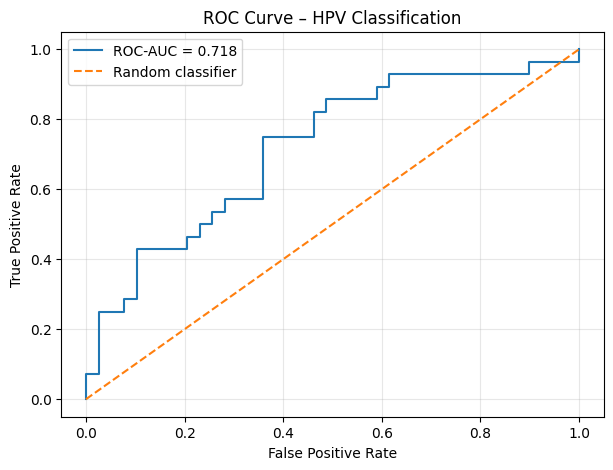

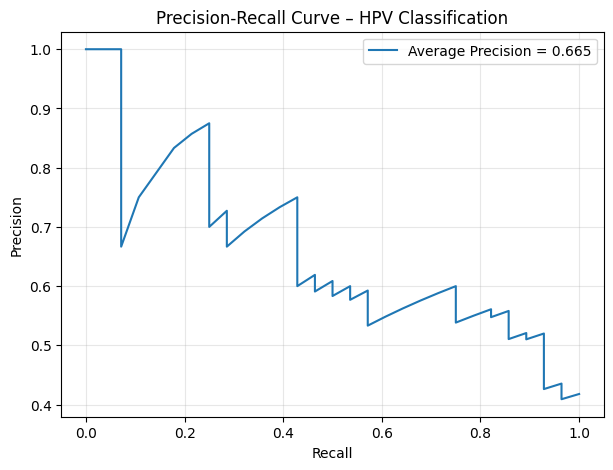

Model and results saved successfully.
Output folder: HPV_GPT2_Results


In [10]:
# HANCOCK GPT-2 CN
# ============================================================
# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
# ============================================================
import os, random, json, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# 2. LOAD AND MERGE HANCOCK CLINICAL/PATHOLOGICAL DATA
# ============================================================
CLINICAL_FILE = "clinical_data.json"
PATHOLOGICAL_FILE = "pathological_data.json"

if not os.path.exists(CLINICAL_FILE):
    if gdown.download(
        id="1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q",
        output=CLINICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download clinical_data.json.")

if not os.path.exists(PATHOLOGICAL_FILE):
    if gdown.download(
        id="1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F",
        output=PATHOLOGICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download pathological_data.json.")

def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        try:
            return pd.DataFrame(obj)
        except ValueError:
            pass
    raise ValueError(f"Could not convert {path} to a table.")

clinical_df = load_json_table(CLINICAL_FILE)
pathological_df = load_json_table(PATHOLOGICAL_FILE)
if ("patient_id" not in clinical_df.columns or
        "patient_id" not in pathological_df.columns):
    raise KeyError("Both JSON files must contain 'patient_id'.")

df = clinical_df.merge(
    pathological_df, on="patient_id", how="left",
    suffixes=("", "_path")
)
print("Clinical shape:", clinical_df.shape)
print("Pathology shape:", pathological_df.shape)
print("Merged shape:", df.shape)

# ============================================================
# 3. SELECT SIX FEATURES AND DEFINE THE HPV TARGET
# ============================================================
def resolve_col(candidates, required=False):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(
            f"Required column not found: {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return None

target_col = resolve_col(
    ["hpv_association_p16", "hpv_association_p16_path"],
    required=True
)
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis", "age_at_initial_diagnosis_path"
    ],
    "sex": ["sex", "sex_path"],
    "smoking_status": ["smoking_status", "smoking_status_path"],
    "primary_tumor_site": [
        "primary_tumor_site", "primary_tumor_site_path"
    ],
    "primarily_metastasis": [
        "primarily_metastasis", "primarily_metastasis_path"
    ],
    "pN_stage": [
        "pN_stage", "pN_stage_path",
        "pathological_N_stage", "pathological_n_stage"
    ]
}
feature_map = {
    name: resolve_col(cols, required=True)
    for name, cols in feature_candidates.items()
}
features = list(feature_candidates.keys())
df = df.dropna(subset=[target_col]).copy()

def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in ["negative", "neg", "0", "false", "no"]:
        return 0
    if s in ["positive", "pos", "1", "true", "yes"]:
        return 1
    try:
        n = float(s)
        if n in [0, 1]:
            return int(n)
    except ValueError:
        pass
    return np.nan

df["HPV_Label"] = df[target_col].apply(normalize_target)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
feature_df = df[[feature_map[c] for c in features]].copy()
feature_df = feature_df.rename(
    columns={feature_map[c]: c for c in features}
)
df = pd.concat([feature_df, df[["HPV_Label"]]], axis=1)
df = df.loc[:, ~df.columns.duplicated()].copy()
df["age_at_initial_diagnosis"] = pd.to_numeric(
    df["age_at_initial_diagnosis"], errors="coerce"
)
print("Patients:", len(df))
print("HPV classes (0=negative, 1=positive):")
print(df["HPV_Label"].value_counts().sort_index())
print("Features:", features)
print("N-stage source:", feature_map["pN_stage"])

# ============================================================
# 4. STRATIFIED TRAIN/VALIDATION/TEST SPLIT (65/15/20)
# ============================================================
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED,
    stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = (
    split.copy() for split in [train_df, val_df, test_df]
)

# ============================================================
# 5. IMPUTE MISSING VALUES USING TRAINING DATA ONLY
# ============================================================
fill_values = {}
for c in features:
    if pd.api.types.is_numeric_dtype(train_df[c]):
        value = train_df[c].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[c].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[c] = value
    for split in [train_df, val_df, test_df]:
        split[c] = split[c].fillna(value)
        if split[c].dtype == object:
            split[c] = split[c].astype(str).replace({
                "": "Unknown", "nan": "Unknown", "None": "Unknown"
            })

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
print("Train:", len(train_df), np.bincount(y_train, minlength=2))
print("Validation:", len(val_df), np.bincount(y_val, minlength=2))
print("Test:", len(test_df), np.bincount(y_test, minlength=2))



# ============================================================
# 6. CREATE CLINICAL NARRATIVES WITH HPV-RELATED CONTEXT
# ============================================================

def patient_to_text(row):

    # 1. AGE
    age = row["age_at_initial_diagnosis"]

    age_sentence = (
        f"The patient was diagnosed at {age} years of age. "
        "Younger age at diagnosis is more commonly associated "
        "with HPV-positive than HPV-negative oropharyngeal cancer."
    )

    # 2. SEX
    sex = str(row["sex"]).strip().lower()

    sex_sentence = (
        f"The patient was {sex}. HPV-positive oropharyngeal "
        "cancer is more frequently observed in men, although "
        "sex alone does not determine HPV status."
    )

    # 3. SMOKING STATUS
    smoking = str(row["smoking_status"]).strip().lower()

    if smoking == "smoker":
        smoking_sentence = (
            "The patient was a current smoker. Smoking history "
            "is more strongly associated with HPV-negative "
            "oropharyngeal cancer."
        )
    elif smoking == "former":
        smoking_sentence = (
            "The patient was a former smoker. Previous tobacco "
            "exposure is more commonly associated with "
            "HPV-negative disease than the typical HPV-positive "
            "clinical profile."
        )
    elif smoking == "non-smoker":
        smoking_sentence = (
            "The patient was a non-smoker. The absence of a "
            "smoking history is more commonly associated with "
            "HPV-positive oropharyngeal cancer."
        )
    else:
        smoking_sentence = (
            "The patient's smoking status was not recorded."
        )

    # 4. PRIMARY TUMOUR SITE
    site = str(row["primary_tumor_site"]).strip()

    if site.lower() == "oropharynx":
        site_sentence = (
            "The primary tumour was located in the oropharynx, "
            "the anatomical site most strongly associated with "
            "HPV-positive head and neck cancer."
        )
    elif site.lower() == "cup":
        site_sentence = (
            "The primary tumour was recorded as carcinoma of "
            "unknown primary, so its anatomical origin was "
            "not identified."
        )
    else:
        site_sentence = (
            f"The primary tumour site was recorded as {site}."
        )

    # 5. METASTATIC STATUS
    metastasis = str(row["primarily_metastasis"]).strip().lower()

    if metastasis == "yes":
        metastasis_sentence = (
            "Distant metastatic disease was recorded. Distant "
            "metastasis at presentation has been reported more "
            "frequently in HPV-negative oropharyngeal cancer."
        )
    elif metastasis == "no":
        metastasis_sentence = (
            "No distant metastatic disease was recorded. "
            "Distant metastasis is less commonly reported at "
            "presentation in HPV-positive disease."
        )
    else:
        metastasis_sentence = (
            "The metastatic status was not recorded."
        )

    # 6. PATHOLOGICAL NODAL STAGE
    n_stage = str(row["pN_stage"]).strip().upper()

    if n_stage == "PN0":
        nodal_sentence = (
            "The pathological nodal stage was pN0, indicating "
            "no regional lymph-node involvement."
        )
    elif n_stage.startswith("PN"):
        nodal_sentence = (
            f"The pathological nodal stage was {n_stage}. "
            "Regional lymph-node involvement, sometimes extensive "
            "despite a small primary tumour, is commonly observed "
            "in HPV-positive oropharyngeal cancer."
        )
    else:
        nodal_sentence = (
            "The pathological nodal stage was not available."
        )

    # COMBINE THE SIX FEATURES
    return " ".join([
        age_sentence,
        sex_sentence,
        smoking_sentence,
        site_sentence,
        metastasis_sentence,
        nodal_sentence
    ])


# Generate narratives for each dataset split
train_texts = [
    patient_to_text(row)
    for _, row in train_df.iterrows()
]

val_texts = [
    patient_to_text(row)
    for _, row in val_df.iterrows()
]

test_texts = [
    patient_to_text(row)
    for _, row in test_df.iterrows()
]


# Inspect an example
print("Example clinical narrative:")
print(train_texts[0])

print("\nNarratives generated:")
print("Training:", len(train_texts))
print("Validation:", len(val_texts))
print("Testing:", len(test_texts))



# ============================================================
# 7. TOKENISE CLINICAL NARRATIVES
# ============================================================

MODEL_NAME = "openai-community/gpt2"

tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

# Calculate token lengths using training narratives only
train_prompt_lengths = [
    len(tokenizer.encode(text, add_special_tokens=False))
    for text in train_texts
]

# Set maximum sequence length
MAX_LENGTH = min(
    1024,
    max(32, int(np.ceil(max(train_prompt_lengths) / 8) * 8))
)

print("Training narratives:", len(train_texts))
print("Validation narratives:", len(val_texts))
print("Test narratives:", len(test_texts))

print("Maximum training narrative length:", max(train_prompt_lengths))
print("Selected maximum sequence length:", MAX_LENGTH)

# Training settings
BATCH_SIZE = 64
EPOCHS = 500
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1

print("\nTraining settings:")
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Dropout:", DROPOUT)



# ============================================================
# 8. BUILD SIMPLE GPT-2 CLINICAL NARRATIVE CLASSIFIER
# ============================================================

class HPVTextDataset(Dataset):

    def __init__(self, texts, labels):
        self.encodings = tokenizer(
            texts,
            max_length=MAX_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
           "input_ids": self.encodings["input_ids"][index],
           "attention_mask": self.encodings["attention_mask"][index],
           "labels": self.labels[index]
    }


# Create datasets
train_dataset = HPVTextDataset(train_texts, y_train)
val_dataset = HPVTextDataset(val_texts, y_val)
test_dataset = HPVTextDataset(test_texts, y_test)


# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# Define the GPT-2 classifier
class HPVNetGPT2(nn.Module):

    def __init__(self):
        super().__init__()

        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)

        # Freeze all GPT-2 parameters
        for param in self.gpt2.parameters():
            param.requires_grad = False

        # Unfreeze the last 4 GPT-2 transformer blocks
        for block in self.gpt2.h[-4:]:
            for param in block.parameters():
                param.requires_grad = True

        # Unfreeze the final layer normalization
        for param in self.gpt2.ln_f.parameters():
            param.requires_grad = True

        hidden_size = self.gpt2.config.hidden_size

        # Simple classification head with 128 hidden units
        self.classifier = nn.Sequential(
            nn.Dropout(DROPOUT),
            nn.Linear(hidden_size, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 2)

        )

    def forward(self, input_ids, attention_mask):

        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = outputs.last_hidden_state

        # Mean pooling
        mask = attention_mask.unsqueeze(-1).float()

        pooled = (hidden_states * mask).sum(dim=1)
        pooled = pooled / mask.sum(dim=1).clamp(min=1)

        return self.classifier(pooled)


# Initialise model
model = HPVNetGPT2().to(device)

# Class-weighted loss
class_counts = np.bincount(y_train, minlength=2)

class_weights = torch.tensor(
    len(y_train) / (2 * class_counts),
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    [
        {"params": model.gpt2.h[-4:].parameters(), "lr": 1e-5},
        {"params": model.gpt2.ln_f.parameters(), "lr": 1e-5},
        {"params": model.classifier.parameters(), "lr": LEARNING_RATE}
    ],
    weight_decay=WEIGHT_DECAY
)

print("GPT-2 backbone: Frozen")
print("Classifier hidden units: 128")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Class weights:", class_weights.cpu().numpy())




# SECTION 9: TRAIN THE MODEL

best_val_loss = float("inf")
best_model_state = None

for epoch in range(EPOCHS):

    # Training
    model.train()


    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(input_ids, attention_mask)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # Validation
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(input_ids, attention_mask)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    # Report results every 50 epochs
    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

    # Save the model with the lowest validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

# Restore the best model
model.load_state_dict(best_model_state)
model.to(device)

print(f"\nBest validation loss: {best_val_loss:.4f}")
print("Best model restored.")



# SECTION 10: TEST SET EVALUATION

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids, attention_mask)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_prob.extend(probabilities[:, 1].cpu().numpy())

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_prob)

# Display results
print("TEST SET RESULTS")
print("----------------")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Precision:         {precision:.4f}")
print(f"Recall:            {recall:.4f}")
print(f"F1-score:          {f1:.4f}")
print(f"ROC-AUC:           {roc_auc:.4f}")

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["HPV-negative", "HPV-positive"],
        zero_division=0
    )
)


# SECTION 11: ROC AND PRECISION-RECALL CURVES

import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
    average_precision_score
)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_true, y_prob)
roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_value:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – HPV Classification")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Precision-Recall curve
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_true, y_prob
)

pr_auc_value = average_precision_score(y_true, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(
    recall_values,
    precision_values,
    label=f"Average Precision = {pr_auc_value:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve – HPV Classification")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# SECTION 12: SAVE THE MODEL AND RESULTS

import os
import pandas as pd

# Create output folder
os.makedirs("HPV_GPT2_Results", exist_ok=True)

# Save trained model
torch.save(
    model.state_dict(),
    "HPV_GPT2_Results/best_gpt2_model.pth"
)

# Save tokenizer
tokenizer.save_pretrained("HPV_GPT2_Results")

# Save test predictions
test_results = pd.DataFrame({
    "Actual_HPV_Status": y_true,
    "Predicted_HPV_Status": y_pred,
    "HPV_Positive_Probability": y_prob
})

test_results.to_csv(
    "HPV_GPT2_Results/test_predictions.csv",
    index=False
)

# Save evaluation metrics
metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Value": [
        accuracy,
        balanced_accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc_value
    ]
})

metrics.to_csv(
    "HPV_GPT2_Results/evaluation_metrics.csv",
    index=False
)

print("Model and results saved successfully.")
print("Output folder: HPV_GPT2_Results")
